#**Data Analytic Showcase for Subscription Finance Analysis**

### Eskwelabs Innovation Fellowship Cohort 10 | Data Modeling
**Chass Miguel E. Mesina and Margrette Sofia M. Hidalgo**

July 2026

#**Executive Summary**

The code below shows realistic revenue events. It tracks monthly revenue, debt, and lost clients. We also wrote planned errors into the math. The text explains how hidden factors like cash stress and tech debt change the numbers.

**This data analytic showcase for subscription finance analysis answers 4 business questions:**
1. What is the distribution of the customer base across industries, and what is the shape of their annual revenue?
2. How does product utilization differ between customers who renew their contracts and customers who cancel?
3. How long does it take different industries to pay their invoices, and what percentage of total revenue falls into collection status?
4. How does the deferred revenue liability decrease over the 12-month fiscal period for an annual contract?

**For further analysis, we also answered these 3 business questions:**
1. Does low initial software utilization indicate a poor product, or does it signal internal IT deployment blockers for smaller clients?
2. Why do accounts with high early engagement cancel their contracts before the year ends?
3. Can we predict account default before contract end by contrasting platform engagement against invoice collection latency?

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

customers = pd.read_csv("customers.csv")
invoices = pd.read_csv("invoices.csv")
payments = pd.read_csv("payments.csv")
product_plans = pd.read_csv("product_plans.csv")
revenue_schedules = pd.read_csv("revenue_schedules.csv")
subscriptions = pd.read_csv("subscriptions.csv")
usage = pd.read_csv("usage_events.csv")

#**Descriptive Analytics**

##**Customer Profiling**

###**Business Question #1**
What is the distribution of the customer base across industries, and what is the shape of their annual revenue?

###**Why does it matter?**
Visually confirms the Categorical distribution for industry assignment and the Log-Normal distribution for company revenue (showing a realistic long tail of massive companies).

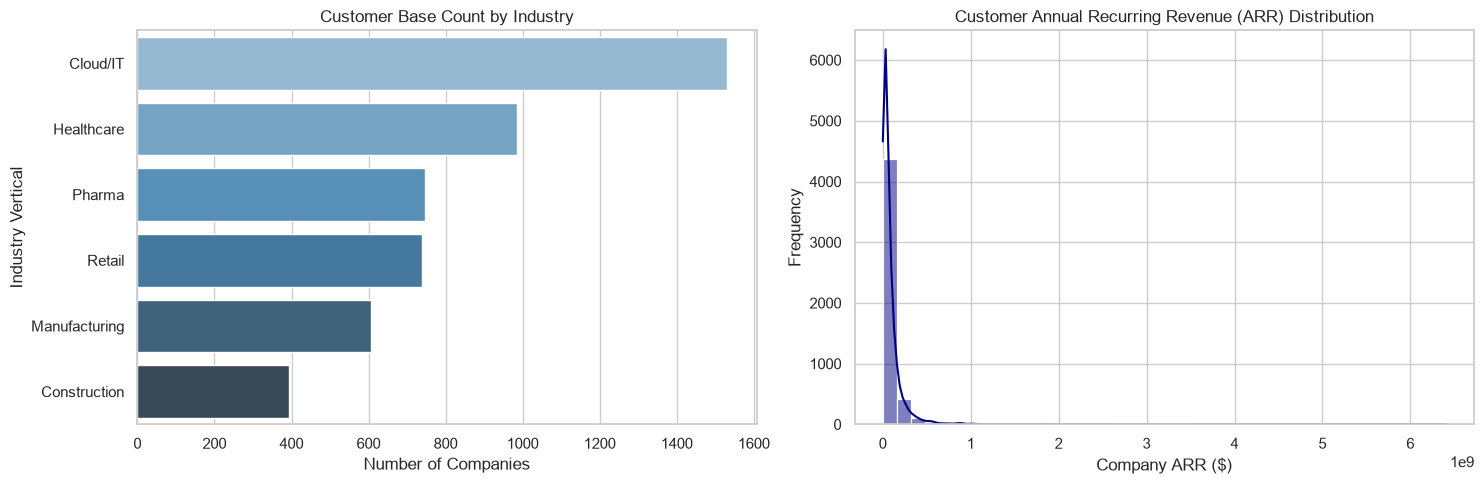

In [2]:
# Two subplots side-by-side
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Plot 1: Customer Base by Industry
sns.countplot(
    data=customers,
    y='industry',
    order=customers['industry'].value_counts().index,
    palette='Blues_d',
    ax=axes[0]
)
axes[0].set_title('Customer Base Count by Industry')
axes[0].set_xlabel('Number of Companies')
axes[0].set_ylabel('Industry Vertical')

# Plot 2: Distribution of Customer Company ARR
sns.histplot(
    customers['company_arr'],
    bins=40,
    kde=True,
    color='navy',
    ax=axes[1]
)
axes[1].set_title('Customer Annual Recurring Revenue (ARR) Distribution')
axes[1].set_xlabel('Company ARR ($)')
axes[1].set_ylabel('Frequency')

plt.tight_layout()
plt.show()

###**Conclusion**
The customer base is heavily concentrated in the Cloud/IT and Healthcare sectors. Furthermore, the revenue distribution shows a heavy right-skew; while most clients bring in a standard baseline revenue, a small handful of massive enterprise contracts drive a significant portion of the total Annual Recurring Revenue (ARR).

##**Churn and Product Utilization**

###**Business Question #2**
How does product utilization differ between customers who renew their contracts and customers who cancel?

###**Why does it matter?**
This shows the statistical footprint of the omitted variables (Executive Champion Turnover and Tech Debt) that your generator produced and then deleted. You will see the visual impact of those hidden confounding variables causing a drop in utilization for churned accounts.

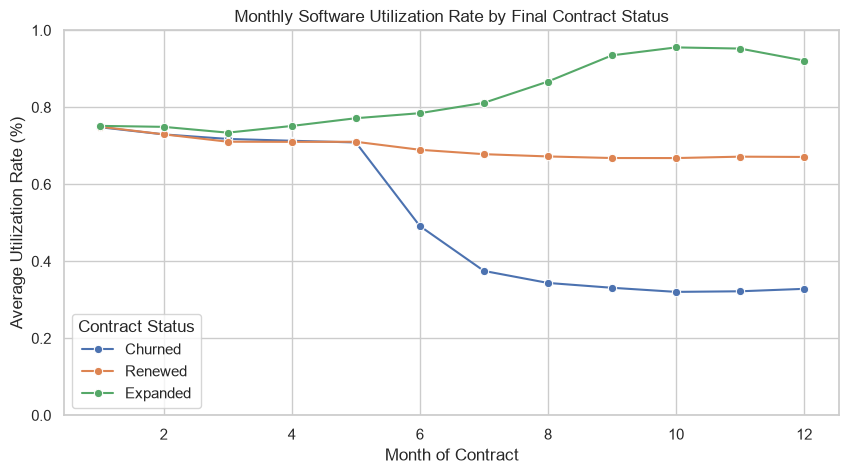

In [3]:
# Joining Usage events with Subscriptions for tagging final contract status
usage_subs = pd.merge(
    usage,
    subscriptions[['subscription_id', 'contract_status']],
    on='subscription_id',
    how='inner'
)

# Plot the average utilization rate per month
plt.figure(figsize=(10, 5))
sns.lineplot(
    data=usage_subs,
    x='month_index',
    y='utilization_rate',
    hue='contract_status',
    marker='o',
    errorbar=None
)
plt.title('Monthly Software Utilization Rate by Final Contract Status')
plt.xlabel('Month of Contract')
plt.ylabel('Average Utilization Rate (%)')
plt.ylim(0, 1)
plt.legend(title='Contract Status')
plt.show()

###**Conclusion**
There is a huge behavioral difference between accounts that renew and those that churn. Customers who eventually cancel their contracts experience a severe, sudden drop in platform usage around the six-month mark. This steep decline serves as a critical early warning sign that an account is highly at risk of churning.

##**Collections and Accounts Receivable**
###**Business Question #3**
How long does it take different industries to pay their invoices, and what percentage of total revenue falls into collection status?

###**Why does it matter?**
This visualizes the Gamma distribution dictating payment delays. More importantly, extreme outliers in this data will represent the hidden "Unobserved Cashflow Distress" variable impacting certain companies.

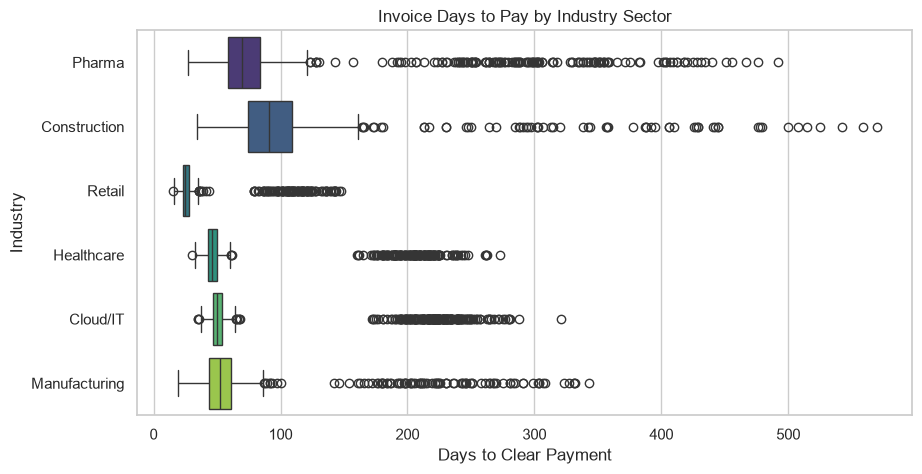

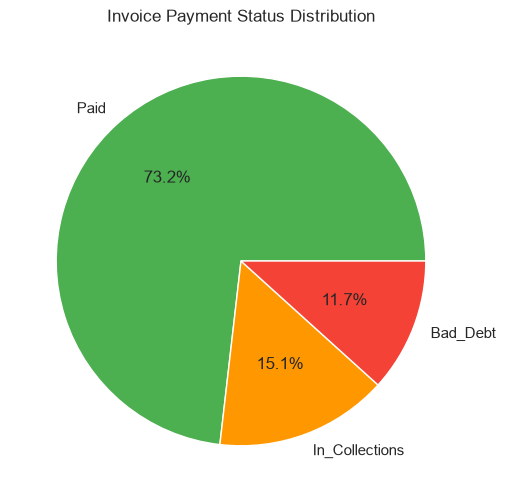

In [4]:
# Joining Payments, Invoices, Subscriptions, and Customers
payments_full = payments.merge(invoices, on='invoice_id') \
                        .merge(subscriptions[['subscription_id', 'customer_id']], on='subscription_id') \
                        .merge(customers[['customer_id', 'industry']], on='customer_id')

# Boxplot for Days to Pay by Industry
plt.figure(figsize=(10, 5))
sns.boxplot(data=payments_full, x='days_to_pay', y='industry', palette='viridis')
plt.title('Invoice Days to Pay by Industry Sector')
plt.xlabel('Days to Clear Payment')
plt.ylabel('Industry')
plt.show()

# Pie chart for Payment Status Breakdown
status_counts = payments['payment_status'].value_counts()
plt.figure(figsize=(6, 6))
plt.pie(
    status_counts,
    labels=status_counts.index,
    autopct='%1.1f%%',
    colors=['#4CAF50', '#FF9800', '#F44336']
)
plt.title('Invoice Payment Status Distribution')
plt.show()

###**Conclusion**
Although nearly 75% of the invoices are paid successfully, late payments are a significant issue in specific institutional sectors like Pharma and Construction, which show extreme delays. This underlying cashflow distress ultimately leads to about 26% of the billed revenue getting stuck in collections or being written off completely as bad debt.

##**Deferred Revenue Burn-Down**

###**Business Question #4**
How does the deferred revenue liability decrease over the 12-month fiscal period for an annual contract?

###**Why does it matter?**
This validates that the generator's corporate accounting ledger works correctly. Revenue from annual contracts must be recognized linearly month-by-month, rather than recognized entirely upfront.

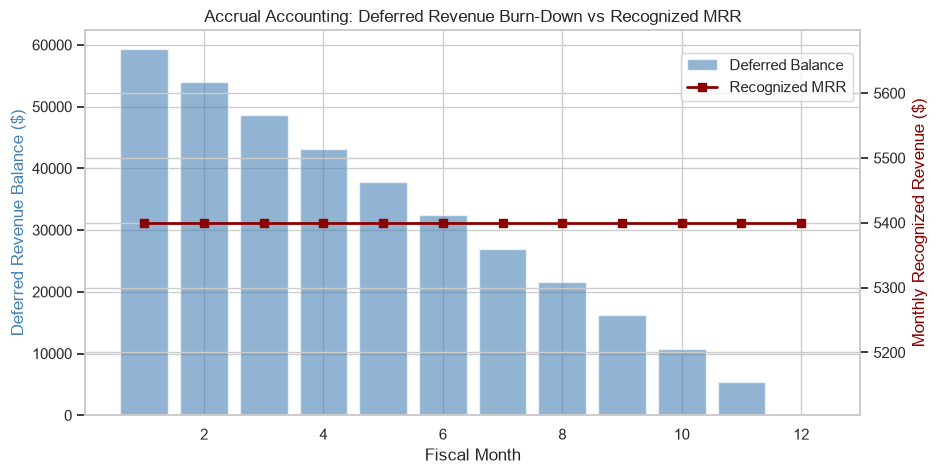

In [5]:
# Selecting a single annual upfront subscription for demonstration (e.g., ID 5001)
sub_demo = revenue_schedules[revenue_schedules['subscription_id'] == 5001]

fig, ax1 = plt.subplots(figsize=(10, 5))

# Bar chart for remaining deferred liability
ax1.bar(
    sub_demo['fiscal_month'],
    sub_demo['deferred_revenue_balance'],
    color='steelblue',
    alpha=0.6,
    label='Deferred Balance'
)
ax1.set_xlabel('Fiscal Month')
ax1.set_ylabel('Deferred Revenue Balance ($)', color='steelblue')

# Line chart for monthly recognized revenue
ax2 = ax1.twinx()
ax2.plot(
    sub_demo['fiscal_month'],
    sub_demo['recognized_mrr'],
    color='darkred',
    marker='s',
    linewidth=2,
    label='Recognized MRR'
)
ax2.set_ylabel('Monthly Recognized Revenue ($)', color='darkred')

# Adding title and align legends
plt.title('Accrual Accounting: Deferred Revenue Burn-Down vs Recognized MRR')
fig.legend(loc="upper right", bbox_to_anchor=(0.9, 0.85))
plt.show()

###**Conclusion**
This chart illustrates the reality of SaaS accrual accounting. Even when an enterprise customer pays for their annual contract entirely upfront (creating a large deferred revenue liability balance), the business only "earns" and recognizes that revenue in equal monthly installments as the software service is successfully delivered throughout the year.

#**Diagnostic Analytics**

###**1. Does low initial software utilization indicate a poor product, or does it signal internal IT deployment blockers for smaller clients?**

###**Why does it matter?**

This separates product-market fit failures from onboarding friction. In our mathematical model, we linked Legacy Tech Debt to company size. Smaller companies have worse IT infrastructure, which artificially suppresses their early software usage. If we only look at overall churn, it might be concluded that the product itself is failing. By plotting early utilization against company size, the analyst can prove that the initial drop is a systemic onboarding issue specific to smaller clients. This insight directs the business to invest in implementation support for small businesses rather than rewriting the core software.

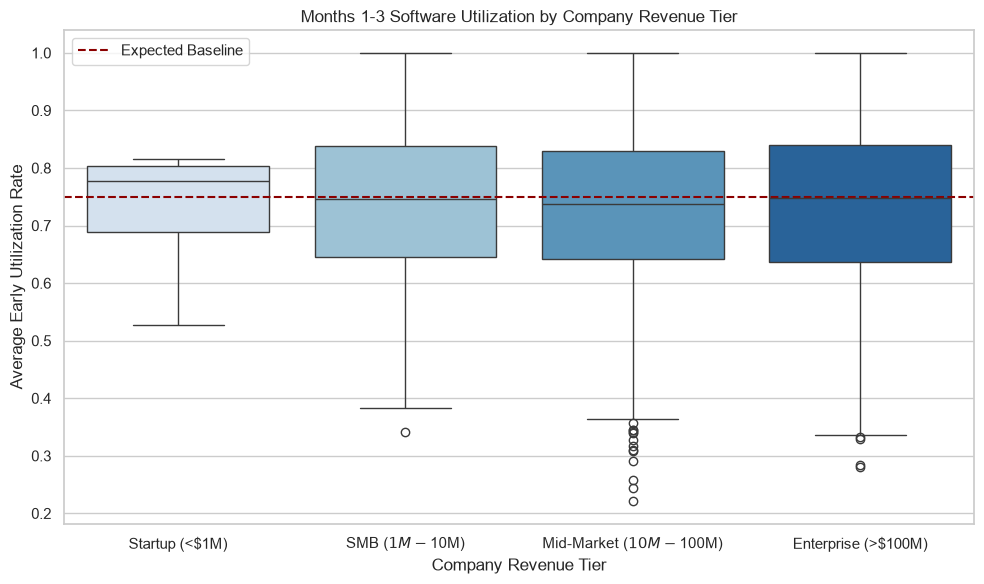

In [6]:
# Average utilization during onboarding (months 1-3) per subscription, joined to company size
early_usage = (
    usage[usage['month_index'] <= 3]
    .groupby('subscription_id')['utilization_rate'].mean()
    .reset_index(name='avg_early_utilization')
)
early_usage_merged = (
    early_usage
    .merge(subscriptions[['subscription_id', 'customer_id']], on='subscription_id')
    .merge(customers[['customer_id', 'company_arr']], on='customer_id')
)

# Define revenue tiers using standard business boundaries
bins = [0, 1e6, 1e7, 1e8, 1e10]
labels = ['Startup (<$1M)', 'SMB ($1M-$10M)', 'Mid-Market ($10M-$100M)', 'Enterprise (>$100M)']

# Create a new categorical column for the revenue tiers
early_usage_merged['arr_tier'] = pd.cut(
    early_usage_merged['company_arr'],
    bins=bins,
    labels=labels
)

# Plot the binned boxplot
plt.figure(figsize=(10, 6))
sns.boxplot(
    data=early_usage_merged,
    x='arr_tier',
    y='avg_early_utilization',
    palette='Blues'
)

plt.title('Months 1-3 Software Utilization by Company Revenue Tier')
plt.xlabel('Company Revenue Tier')
plt.ylabel('Average Early Utilization Rate')

# Add the expected baseline for reference
plt.axhline(y=0.75, color='darkred', linestyle='--', label='Expected Baseline')
plt.legend()
plt.tight_layout()
plt.show()

###**Conclusion**
Small businesses experience significantly more friction during initial onboarding than enterprise clients. This confirms that low early utilization acts as a symptom of internal deployment blockers, rather than indicating a failure of the core product.

###**2. Why do accounts with high early engagement cancel their contracts before the year ends?**

###**Why does it matter?**

This tracks the behavioral shock of Executive Champion Turnover. By isolating churned accounts that had high early engagement, we can expose a distinct mid-year usage cliff. This shows that some churn is driven by sudden organizational shifts rather than gradual product dissatisfaction, prompting Revenue Operations to build alerts for sudden usage drops rather than relying solely on low average usage.

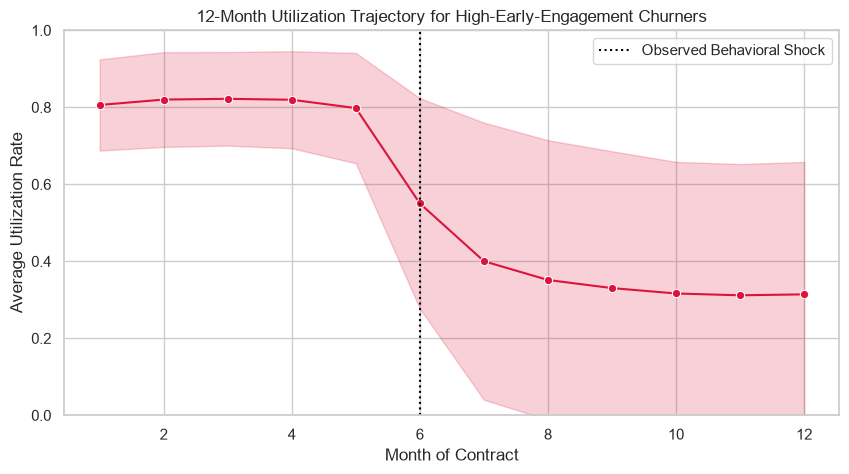

In [7]:
# Identify churned subscriptions
churned_subs = subscriptions[subscriptions['contract_status'] == 'Churned'][['subscription_id']]

# Calculate their early usage (Months 1-5)
churned_usage = usage.merge(churned_subs, on='subscription_id')
early_churned_usage = churned_usage[churned_usage['month_index'] <= 5].groupby('subscription_id')['utilization_rate'].mean().reset_index()

# Filter for accounts that had HIGH early usage (e.g., > 70%) despite eventually churning
high_early_churners = early_churned_usage[early_churned_usage['utilization_rate'] >= 0.70]['subscription_id']

# Get the full 12-month trajectory for this specific cohort
shock_cohort_usage = usage[usage['subscription_id'].isin(high_early_churners)]

# Plot the trajectory
plt.figure(figsize=(10, 5))
sns.lineplot(
    data=shock_cohort_usage,
    x='month_index',
    y='utilization_rate',
    estimator='mean',
    errorbar='sd',
    marker='o',
    color='crimson'
)
plt.title('12-Month Utilization Trajectory for High-Early-Engagement Churners')
plt.xlabel('Month of Contract')
plt.ylabel('Average Utilization Rate')
plt.ylim(0, 1)
plt.axvline(x=6, color='black', linestyle=':', label='Observed Behavioral Shock')
plt.legend()
plt.show()

###**Conclusion**
Accounts with perfect early usage do not churn due to gradual product dissatisfaction. The sudden mid-year cliff isolates a distinct behavioral shock, such as the departure of the executive who originally purchased the software.

###**3. Can we predict account default before contract end by contrasting platform engagement against invoice collection latency?**

###**Why does it matter?**

This isolates the Unobserved Cashflow Distress variable. In a real company, Product teams track usage, while Finance teams track payments. If these datasets remain isolated, the business misinterprets financial default as product churn. By plotting payment latency against software utilization, the analyst identifies a cluster of accounts that use the software heavily but fail to pay their invoices. This proves the cancellation is an involuntary financial default, meaning the account requires intervention from the Collections department, not Customer Success.

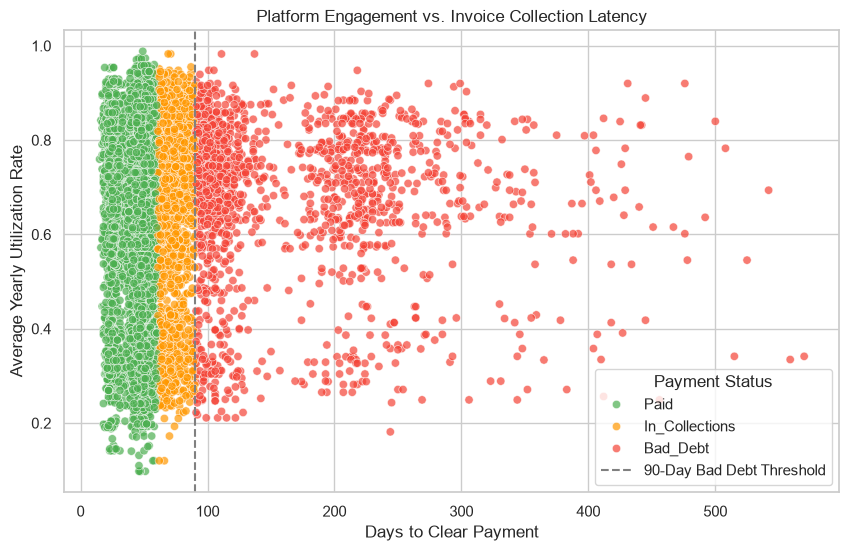

In [8]:
# Calculate total average utilization across the whole year per subscription
avg_yearly_usage = usage.groupby('subscription_id')['utilization_rate'].mean().reset_index()

# Merge payments with invoices to get subscription_id
payments_invoices = payments.merge(invoices[['invoice_id', 'subscription_id']], on='invoice_id')

# Merge the usage data with the payment data
financial_health = payments_invoices.merge(avg_yearly_usage, on='subscription_id')

# Filter for the specific statuses we want to compare
target_statuses = ['Paid', 'In_Collections', 'Bad_Debt']
financial_health_filtered = financial_health[financial_health['payment_status'].isin(target_statuses)]

# Plot Days to Pay vs Average Utilization Rate
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=financial_health_filtered,
    x='days_to_pay',
    y='utilization_rate',
    hue='payment_status',
    palette={'Paid': '#4CAF50', 'In_Collections': '#FF9800', 'Bad_Debt': '#F44336'},
    alpha=0.7
)
plt.title('Platform Engagement vs. Invoice Collection Latency')
plt.xlabel('Days to Clear Payment')
plt.ylabel('Average Yearly Utilization Rate')
plt.axvline(x=90, color='grey', linestyle='--', label='90-Day Bad Debt Threshold')
plt.legend(title='Payment Status')
plt.show()

###**Conclusion**
High software usage does not guarantee contract renewal if the underlying company lacks capital. We can predict specific contract defaults by identifying accounts that actively consume server resources while failing to clear their invoices, isolating financial default from product-driven churn.

#**Overall Conclusion**

This data analytic showcase demonstrates that synthetic data modeling can successfully replicate the complex structural mechanics of Enterprise B2B SaaS subscription finance.

By grounding our data generation in explicit mathematical distributions—such as Log-Normal company revenues, Gamma invoice clearing delays, and mean-reverting AR(1) platform usage, we were able to produce a realistic environment that supports both standard business intelligence reporting and advanced diagnostic analytics. Furthermore, by engineering unobserved latent factors (such as legacy tech debt, executive turnover, and cashflow distress) and subsequently dropping them prior to export, we successfully introduced realistic confounding bias.

The exploratory data analysis proves that analysts can uncover hidden operational bottlenecks, behavioral churn cliffs, and involuntary financial defaults simply by cross-referencing observable metrics. This project validates that robust synthetic datasets provide an effective, privacy-safe foundation for training data professionals to navigate ambiguity and solve real-world business problems.